In [1]:
%matplotlib inline
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'uni_agent').is_dir() and (p / 'meta/plot').is_dir())
PLOT = REPO / 'meta/plot'
DATA = PLOT / 'data/verified_characterization_2hosts_20261019.csv'
PROVENANCE = DATA.with_suffix('.provenance.json')
FIGURES = PLOT / 'figure'
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_style('ticks')
sns.set_style({'font.family': ['Roboto', 'DejaVu Sans'], 'font.size': 12})
sns.set_context('paper', font_scale=2,
                rc={'lines.linewidth': 3, 'lines.markersize': 10})
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'svg.fonttype': 'none',
})
PALETTE = {
    'blue_main': '#0F4D92', 'blue_secondary': '#3775BA',
    'green_3': '#8BCF8B', 'green_dark': '#397A39',
    'red_strong': '#B64342', 'neutral': '#CFCECE',
    'teal': '#42949E', 'violet': '#9A4D8E',
}

In [2]:
provenance = json.loads(PROVENANCE.read_text())
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == provenance['sha256']
frame = pd.read_csv(DATA).sort_values('concurrency_episodes').reset_index(drop=True)
assert frame.concurrency_episodes.tolist() == [64, 128, 256, 512]
assert frame.terminal_attempts.eq(1024).all()
assert (frame.verified_attempts + frame.incomplete_verifications).eq(1024).all()
assert frame.usable_trajectories.tolist() == [1024, 1024, 1024, 1022]
frame['usable_samples_per_minute'] = (
    frame.usable_trajectories * 60 / frame.rollout_wall_seconds
)
for metric in ('sandbox_cpu', 'sandbox_ram'):
    assert frame[f'{metric}_mean_pct'].between(0, 100).all()
    assert frame[f'{metric}_peak_5s_pct'].between(0, 100).all()
    assert (frame[f'{metric}_peak_5s_pct'] >= frame[f'{metric}_mean_pct']).all()

summary = pd.DataFrame({
    'Concurrency': frame.concurrency_episodes,
    'Usable samples': frame.usable_trajectories,
    'Usable samples / min': frame.usable_samples_per_minute,
    'Active requests mean': frame.active_requests_total_mean,
    'CPU mean (%)': frame.sandbox_cpu_mean_pct,
    'CPU peak ~5 s (%)': frame.sandbox_cpu_peak_5s_pct,
    'Host RAM mean (%)': frame.sandbox_ram_mean_pct,
    'Host RAM peak ~5 s (%)': frame.sandbox_ram_peak_5s_pct,
}).set_index('Concurrency')
display(summary.round(2))

,Usable samples,Usable samples / min,Active requests mean,CPU mean (%),CPU peak ~5 s (%),Host RAM mean (%),Host RAM peak ~5 s (%)
Concurrency,,,,,,,
64,1024,54.94,10.00,14.81,27.76,4.59,6.57
128,1024,82.91,19.54,24.80,50.10,7.18,10.59
256,1024,123.81,50.09,45.41,96.22,11.60,18.75
512,1022,126.14,95.23,59.36,99.75,18.59,31.25


**Metric definitions**

- The measured window runs from `model_ready_at` to `model_ready_at + rollout_wall_seconds`.
  Model startup and cleanup are excluded; tool execution and verification waits remain included.
- Usable throughput is stored usable trajectories divided by rollout seconds, multiplied by 60.
  It is distinct from completed reward-verification throughput. Usable counts are
  **1,024 / 1,024 / 1,024 / 1,022** at C=64 / 128 / 256 / 512.
- Active requests are running inference requests **summed over both TP4 replicas** and averaged
  over paired approximately five-second samples. They use the right-hand count axis.
- CPU uses all **192 sandbox vCPUs**, excludes idle/I/O wait, and counts VM guest ticks once.
  Its mean is duration-weighted over both-host coverage.
- Host RAM utilization is **100 × Σ(MemTotal − MemAvailable) / Σ(MemTotal)** across the two
  sandbox hosts, including the OS, runtime, and VMs. This is distinct from KV-cache usage
  or anonymous process memory. Its mean is duration-weighted over both-host coverage.
- CPU/RAM peaks are maxima of complete, aligned five-second fleet-mean bins. Solid bar height
  is the mean; the hatched upper segment reaches the peak, rather than adding another peak value.
- These are observed sampled peaks, not confidence intervals. There is one observation per point.

Frozen `.provenance.json` metadata retains source hashes, rollout windows, aggregation rules,
and sample coverage. No remote access is used to render the figure.

In [ ]:
def mean_peak_bar(axis, positions, means, peaks, color, edgecolor=None):
    """One bar: solid base to mean, hatched extension from mean to peak."""
    edgecolor = edgecolor or color
    axis.bar(positions, means, width=.23, color=color, linewidth=0, zorder=3)
    axis.bar(positions, peaks - means, bottom=means, width=.23,
             facecolor=to_rgba(color, .18), edgecolor=edgecolor,
             hatch='///', linewidth=0, zorder=3)

def draw_characterization(data):
    x = np.arange(len(data))
    fig, (throughput, resources) = plt.subplots(1, 2, figsize=(10, 4.3))
    fig.subplots_adjust(left=.13, right=.83, bottom=.25, top=.72, wspace=.67)
    requests = resources.twinx()
    requests.patch.set_visible(False)

    usable = throughput.bar(
        x, data.usable_samples_per_minute, width=.55,
        color=PALETTE['blue_secondary'], zorder=3)
    throughput.bar_label(usable, fmt='%.1f', padding=4, fontsize=12)
    throughput.set_title('SWE-bench Verified · two hosts', loc='left', fontsize=14, pad=12)
    throughput.set_ylabel('Throughput\n(usable samples / min)', fontsize=17.6)
    throughput.set_ylim(0, 150)
    throughput.set_yticks([0, 50, 100, 150])

    requests.bar(
        x - .25, data.active_requests_total_mean, width=.23,
        color=PALETTE['blue_main'], zorder=3)
    mean_peak_bar(resources, x, data.sandbox_cpu_mean_pct, data.sandbox_cpu_peak_5s_pct,
                  PALETTE['green_3'], PALETTE['green_dark'])
    mean_peak_bar(resources, x + .25, data.sandbox_ram_mean_pct, data.sandbox_ram_peak_5s_pct,
                  PALETTE['violet'])
    resources.set_ylabel('CPU / RAM utilization (%)', fontsize=17.6)
    resources.set_ylim(0, 105)
    resources.set_yticks([0, 25, 50, 75, 100])
    requests.set_ylabel('Mean active requests', fontsize=17.6, color=PALETTE['blue_main'])
    requests.set_ylim(0, 128)
    requests.set_yticks([0, 32, 64, 96, 128])
    requests.tick_params(axis='y', colors=PALETTE['blue_main'])
    requests.spines['right'].set_color(PALETTE['blue_main'])

    for axis in (throughput, resources):
        axis.set_xticks(x, data.concurrency_episodes.astype(str))
        axis.set_xlabel('# Concurrent Traj.', fontsize=16)
        axis.tick_params(labelsize=14)
        axis.grid(axis='y', color=PALETTE['neutral'], linewidth=.8, alpha=.4, zorder=0)
        axis.set_axisbelow(True)
        sns.despine(ax=axis)
    requests.tick_params(labelsize=14)
    sns.despine(ax=requests, left=True, right=False)

    handles = [
        Patch(facecolor=PALETTE['blue_secondary'], label='Usable samples'),
        Patch(facecolor=PALETTE['blue_main'], label='Active requests (mean)'),
        Patch(facecolor=PALETTE['green_3'], label='CPU utilization'),
        Patch(facecolor=PALETTE['violet'], label='RAM utilization'),
        Patch(facecolor='#777777', label='Mean (solid)'),
        Patch(facecolor='white', edgecolor='#777777', hatch='///', label='Peak (hatched)'),
    ]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, 1.13),
               ncol=3, fontsize=15.5, columnspacing=1, handlelength=1.05,
               labelspacing=.3, frameon=False)
    fig.text(.5, .01, 'CPU/RAM: solid base = mean; hatched extension ends at the peak. Rollout windows only.',
             ha='center', fontsize=10)
    return fig

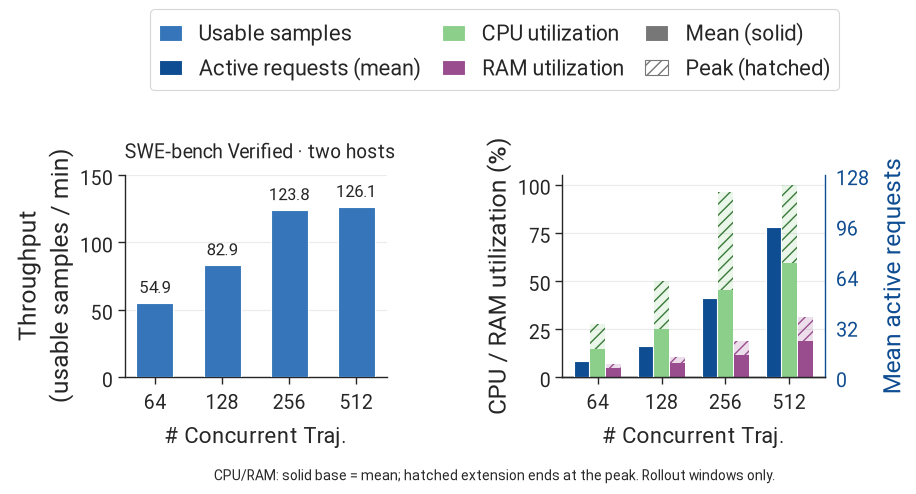

Saved: meta/plot/figure/concurrency_characterization_verified.png, meta/plot/figure/concurrency_characterization_verified.pdf, meta/plot/figure/concurrency_characterization_verified.svg


In [4]:
figure = draw_characterization(frame)
output = FIGURES / 'concurrency_characterization_verified'
for extension in ('png', 'pdf', 'svg'):
    figure.savefig(output.with_suffix('.' + extension), dpi=300,
                   facecolor='white', bbox_inches='tight')
display(figure)
plt.close(figure)
print('Saved:', ', '.join(str(output.with_suffix('.' + ext).relative_to(REPO))
                          for ext in ('png', 'pdf', 'svg')))